# 01 - Exploration des données (EDA) : NEU-CLS

**Objectifs**
1. Vérifier l'intégrité du dataset (nombre d'images, tailles, format, étiquettes).
2. Visualiser la distribution des classes, globalement et par subset (train / val / test).
3. Observer des exemples de chaque classe et les statistiques d'intensité.
4. Analyser les doublons (exacts et quasi-doublons) et justifier le seuil choisi.
5. Explorer les boîtes englobantes (YOLO), en préparation de l'extension *localisation*.

> Ce notebook **ne contient aucune logique métier** : il lit les fichiers produits par
> `scripts/prepare_splits.py`. Les figures sont sauvegardées dans `ai-engine/reports/figures/`.
>
> **Règle anti-fuite** : les statistiques servant au prétraitement (moyenne / écart-type
> de normalisation) sont calculées **sur le train uniquement**. Les images de test ne sont
> affichées ici que pour contrôler l'intégrité du split, jamais pour faire des choix.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from PIL import Image

from ivai.config import FIGURES_DIR, NEU_RAW_DIR, SPLITS_DIR, load_data_config

cfg = load_data_config()
CLASSES = list(cfg.classes)
SPLITS = ["train", "val", "test"]
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Palette catégorielle validée (daltonisme) - ordre fixe, jamais recyclé.
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
SPLIT_COLORS = dict(zip(SPLITS, SERIES[:3]))
TEXT, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": TEXT, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold",
})

def save(fig, name):
    path = FIGURES_DIR / name
    fig.savefig(path, facecolor="white")
    print(f"saved -> {path.relative_to(FIGURES_DIR.parents[1])}")

index = pd.read_csv(SPLITS_DIR / "neu_cls_index.csv")
dups = pd.read_csv(SPLITS_DIR / "neu_cls_duplicates.csv")
boxes = pd.read_csv(SPLITS_DIR / "neu_cls_boxes.csv")
meta = json.loads((SPLITS_DIR / "split_meta.json").read_text(encoding="utf-8"))
print(f"{len(index)} images, {len(boxes)} boîtes, {len(dups)} paires de doublons confirmées")
print(json.dumps({k: meta[k] for k in ["seed", "val_ratio", "test_ratio", "counts"]}, indent=1))

1800 images, 4189 boîtes, 2 paires de doublons confirmées
{
 "seed": 42,
 "val_ratio": 0.15,
 "test_ratio": 0.15,
 "counts": {
  "train": 1260,
  "val": 270,
  "test": 270
 }
}


## 1. Intégrité du dataset

In [2]:
summary = pd.Series({
    "Nombre d'images": len(index),
    "Nombre de classes": index["label"].nunique(),
    "Tailles (l x h) distinctes": index[["width", "height"]].drop_duplicates().apply(lambda r: f"{r.width}x{r.height}", axis=1).tolist(),
    "Modes PIL": index["mode"].unique().tolist(),
    "Contenu en niveaux de gris": f"{index['is_grayscale'].mean():.1%}",
    "Taille fichier (Ko) min / médiane / max": f"{index.file_bytes.min()/1024:.1f} / {index.file_bytes.median()/1024:.1f} / {index.file_bytes.max()/1024:.1f}",
    "Images sans boîte YOLO": int((index["n_boxes"] == 0).sum()),
    "Classe du nom absente des boîtes YOLO": int(index["box_contains_label"].eq(False).sum()),
    "Images multi-défauts (classes secondaires)": f"{int(index['has_secondary_defects'].sum())} ({index['has_secondary_defects'].mean():.1%})",
    "Noms de fichiers uniques": index["filename"].is_unique,
})
summary.to_frame("valeur")

,valeur
Nombre d'images,1800
Nombre de classes,6
Tailles (l x h) distinctes,[200x200]
Modes PIL,[RGB]
Contenu en niveaux de gris,100.0%
Taille fichier (Ko) min / médiane / max,5.6 / 14.9 / 23.6
Images sans boîte YOLO,0
Classe du nom absente des boîtes YOLO,0
Images multi-défauts (classes secondaires),123 (6.8%)
Noms de fichiers uniques,True


## 2. Distribution des classes

split,train,val,test,total
label,,,,
crazing,210,45,45,300
inclusion,210,45,45,300
patches,210,45,45,300
pitted_surface,210,45,45,300
rolled-in_scale,210,45,45,300
scratches,210,45,45,300


saved -> reports\figures\fig01_class_distribution.png


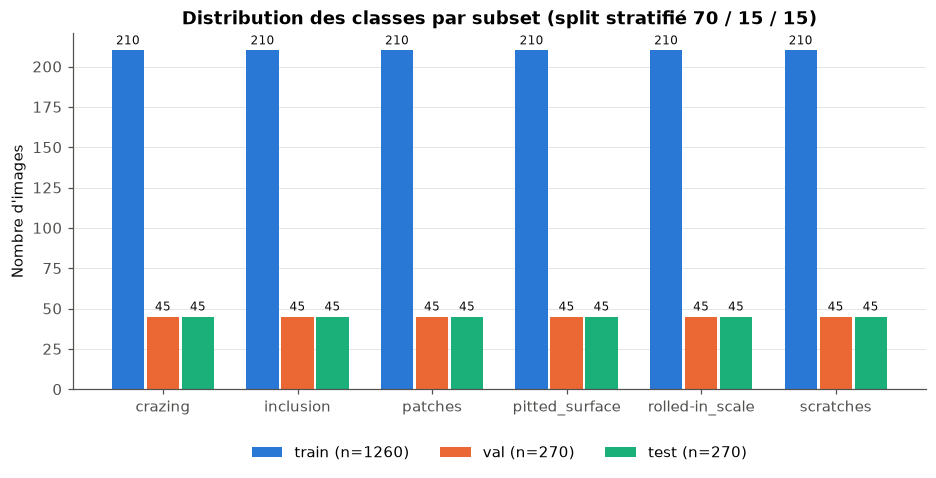

In [3]:
ct = pd.crosstab(index["label"], index["split"]).reindex(index=CLASSES, columns=SPLITS)
display(ct.assign(total=ct.sum(axis=1)))

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(CLASSES))
w = 0.26
for k, split in enumerate(SPLITS):
    bars = ax.bar(x + (k - 1) * w, ct[split], width=w - 0.02, color=SPLIT_COLORS[split], label=f"{split} (n={ct[split].sum()})")
    ax.bar_label(bars, padding=2, fontsize=8, color=TEXT)
ax.set_xticks(x, CLASSES)
ax.set_ylabel("Nombre d'images")
ax.set_title("Distribution des classes par subset (split stratifié 70 / 15 / 15)")
ax.legend(frameon=False, ncols=3, loc="upper center", bbox_to_anchor=(0.5, -0.12))
ax.grid(axis="x", visible=False)
save(fig, "fig01_class_distribution.png")
plt.show()

## 3. Exemples d'images par classe (train uniquement)

saved -> reports\figures\fig02_samples_per_class.png


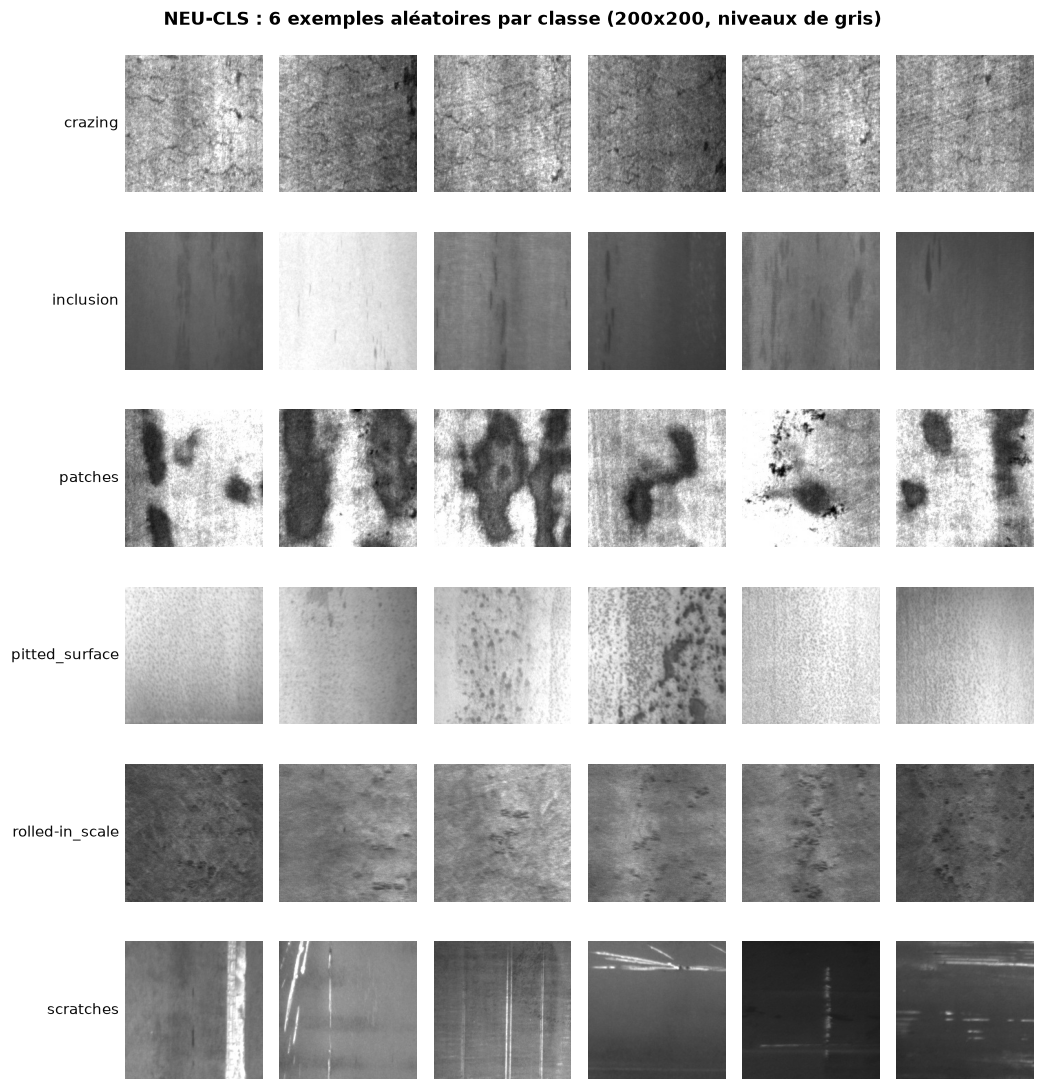

In [4]:
rng = np.random.default_rng(cfg.seed)
n_per_class = 6
fig, axes = plt.subplots(len(CLASSES), n_per_class, figsize=(n_per_class * 1.6, len(CLASSES) * 1.7))
for r, cls in enumerate(CLASSES):
    files = index.query("label == @cls and split == 'train'")["relpath"].to_numpy()
    for c, rel in enumerate(rng.choice(files, n_per_class, replace=False)):
        ax = axes[r, c]
        ax.imshow(Image.open(NEU_RAW_DIR / rel).convert("L"), cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
    axes[r, 0].set_ylabel(cls, rotation=0, ha="right", va="center", fontsize=10, color=TEXT)
fig.suptitle("NEU-CLS : 6 exemples aléatoires par classe (200x200, niveaux de gris)", fontweight="bold")
fig.tight_layout()
save(fig, "fig02_samples_per_class.png")
plt.show()

## 4. Statistiques d'intensité

Si une classe se distingue surtout par sa **luminosité globale**, un CNN peut apprendre
ce raccourci au lieu de la forme du défaut. Cette analyse oriente le choix de la
normalisation et des augmentations (variations de luminosité / contraste).

saved -> reports\figures\fig03_intensity_by_class.png


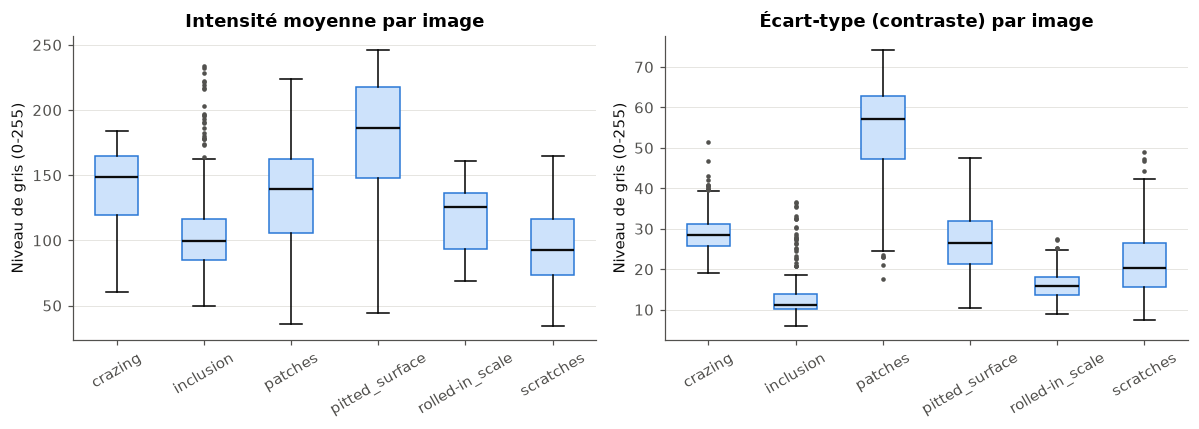

mean_intensity       std_intensity      
                          mean   std          mean   std
label                                                   
crazing                  141.1  28.7          29.1   4.8
inclusion                106.4  33.9          13.0   5.5
patches                  132.5  43.1          54.2  12.3
pitted_surface           176.7  49.3          26.7   7.7
rolled-in_scale          117.9  24.6          16.1   3.5
scratches                 95.1  29.1          21.7   8.3

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "mean_intensity", "Intensité moyenne par image"),
                       (axes[1], "std_intensity", "Écart-type (contraste) par image")]:
    data = [index.loc[index.label == c, col] for c in CLASSES]
    bp = ax.boxplot(data, tick_labels=CLASSES, widths=0.5, patch_artist=True,
                    medianprops={"color": TEXT, "linewidth": 1.5},
                    flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none"})
    for patch in bp["boxes"]:
        patch.set(facecolor="#cde2fb", edgecolor=SERIES[0])
    ax.set_title(title)
    ax.set_ylabel("Niveau de gris (0-255)")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig03_intensity_by_class.png")
plt.show()

stats = index.groupby("label")[["mean_intensity", "std_intensity"]].agg(["mean", "std"]).reindex(CLASSES).round(1)
display(stats)

In [6]:
# Statistiques de normalisation calculées sur le TRAIN uniquement (pixels, échelle 0-1).
train_files = index.loc[index.split == "train", "relpath"]
pix = np.stack([np.asarray(Image.open(NEU_RAW_DIR / p).convert("L"), dtype=np.float64) / 255.0 for p in train_files])
train_mean, train_std = float(pix.mean()), float(pix.std())
print(f"Train ({len(train_files)} images) : mean = {train_mean:.4f}, std = {train_std:.4f}")
_ = (SPLITS_DIR / "train_pixel_stats.json").write_text(
    json.dumps({"mean": train_mean, "std": train_std, "n_images": int(len(train_files))}, indent=2), encoding="utf-8")

Train (1260 images) : mean = 0.5043, std = 0.2125


## 5. Image moyenne par classe (train)

L'image moyenne révèle d'éventuels **biais spatiaux** (par exemple une orientation
dominante des rayures), utiles pour choisir des augmentations géométriques plausibles.

saved -> reports\figures\fig04_mean_image_per_class.png


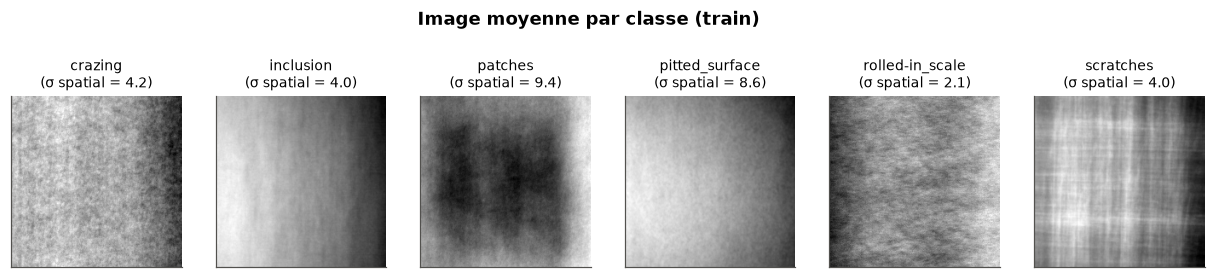

In [7]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(14, 2.8))
for ax, cls in zip(axes, CLASSES):
    files = index.query("label == @cls and split == 'train'")["relpath"]
    mean_img = np.mean([np.asarray(Image.open(NEU_RAW_DIR / p).convert("L"), dtype=np.float64) for p in files], axis=0)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(f"{cls}\n(σ spatial = {mean_img.std():.1f})", fontsize=9, fontweight="normal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Image moyenne par classe (train)", fontweight="bold", y=1.05)
save(fig, "fig04_mean_image_per_class.png")
plt.show()

## 6. Doublons et quasi-doublons

Méthode (voir `ivai/data/duplicates.py`) :
1. Doublons exacts : hash SHA-256 des pixels décodés.
2. Candidats quasi-doublons : distance de Hamming entre pHash (64 bits), minimum sur les
   8 rotations / symétries, `<= phash_max_distance`.
3. Confirmation : corrélation de Pearson des pixels `>= min_pixel_correlation`.

L'histogramme ci-dessous montre, pour chaque image, la distance pHash à son **plus proche
voisin**. Il permet de vérifier que le seuil sépare bien les copies des images distinctes.

saved -> reports\figures\fig05_nearest_phash_distance.png


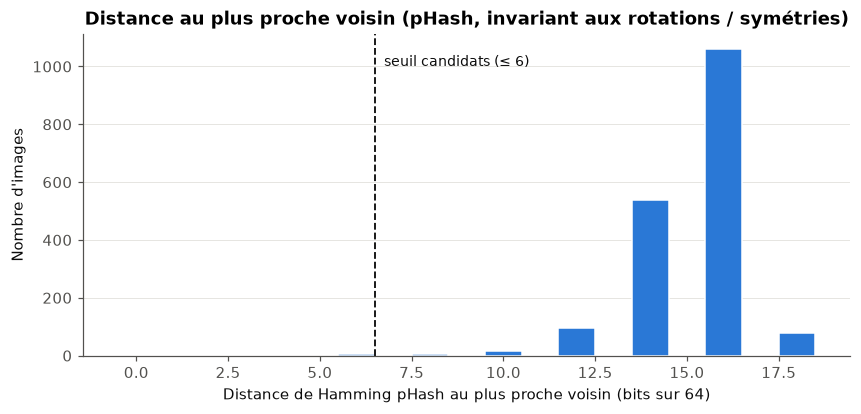

count    1800.00
mean       15.15
std         1.64
min         0.00
25%        14.00
50%        16.00
75%        16.00
max        18.00

Images avec un voisin à distance <= 6 : 8
Paires confirmées : 2 (exactes : 1, quasi : 1)


,i,j,kind,hamming,correlation,transform,file_i,file_j,label_i,label_j
0,603,607,exact,0,1.000000,0,patches_101.jpg,patches_105.jpg,patches,patches
1,1648,1664,near,2,0.957452,1,scratches_232.jpg,scratches_247.jpg,scratches,scratches


In [8]:
thr = cfg.phash_max_distance
fig, ax = plt.subplots(figsize=(9, 3.8))
d = index["nearest_phash_distance"]
ax.hist(d, bins=np.arange(-0.5, d.max() + 1.5, 1), color=SERIES[0], edgecolor="white", linewidth=1)
ax.axvline(thr + 0.5, color=TEXT, linestyle="--", linewidth=1.2)
ax.annotate(f"seuil candidats (≤ {thr})", xy=(thr + 0.5, ax.get_ylim()[1] * 0.9), xytext=(6, 0),
            textcoords="offset points", color=TEXT, fontsize=9)
ax.set_xlabel("Distance de Hamming pHash au plus proche voisin (bits sur 64)")
ax.set_ylabel("Nombre d'images")
ax.set_title("Distance au plus proche voisin (pHash, invariant aux rotations / symétries)")
ax.grid(axis="x", visible=False)
save(fig, "fig05_nearest_phash_distance.png")
plt.show()

print(d.describe().round(2).to_string())
print(f"\nImages avec un voisin à distance <= {thr} : {(d <= thr).sum()}")
print(f"Paires confirmées : {len(dups)} (exactes : {(dups.kind == 'exact').sum() if len(dups) else 0}, "
      f"quasi : {(dups.kind == 'near').sum() if len(dups) else 0})")
display(dups.head(20) if len(dups) else "Aucune paire confirmée")

4 paires candidates (pHash <= 6) : 2 confirmées, 2 rejetées (corrélation < 0.95)
Corrélation max parmi les rejetées : 0.421


,file_i,file_j,label_i,label_j,split_i,split_j,hamming,correlation,confirmé
0,patches_101.jpg,patches_105.jpg,patches,patches,train,train,0,1.000,True
1,scratches_232.jpg,scratches_247.jpg,scratches,scratches,train,train,2,0.957,True
2,scratches_221.jpg,scratches_243.jpg,scratches,scratches,test,val,6,0.421,False
3,scratches_27.jpg,scratches_295.jpg,scratches,scratches,train,val,6,0.318,False


saved -> reports\figures\fig06_candidate_pairs.png


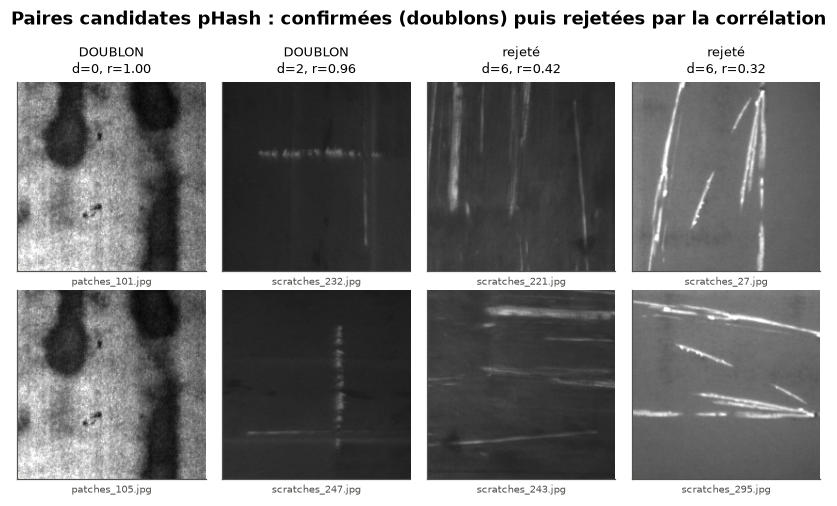

In [9]:
# Toutes les paires candidates (distance pHash <= seuil), confirmées ou rejetées par la corrélation.
from ivai.data.duplicates import compute_hashes, min_hamming_all_pairs, pixel_correlation, TRANSFORMS
from ivai.data.index import load_gray

imgs = [load_gray(NEU_RAW_DIR / p) for p in index["relpath"]]
dist, best_t = min_hamming_all_pairs(compute_hashes(imgs))
sym = np.minimum(dist, dist.T)
iu = np.triu_indices(len(imgs), 1)
cand = [(i, j) for i, j in zip(*iu) if sym[i, j] <= thr]
rows = []
for i, j in cand:
    if dist[i, j] <= dist[j, i]:
        a, b = imgs[i], TRANSFORMS[best_t[i, j]](imgs[j])
    else:
        a, b = imgs[j], TRANSFORMS[best_t[j, i]](imgs[i])
    r = 1.0 if index.pixel_sha256[i] == index.pixel_sha256[j] else pixel_correlation(a, np.ascontiguousarray(b))
    rows.append({"file_i": index.filename[i], "file_j": index.filename[j], "label_i": index.label[i], "label_j": index.label[j],
                 "split_i": index.split[i], "split_j": index.split[j], "hamming": int(sym[i, j]), "correlation": round(r, 3),
                 "confirmé": r >= cfg.min_pixel_correlation})
cand_df = pd.DataFrame(rows).sort_values(["confirmé", "hamming", "correlation"], ascending=[False, True, False])
print(f"{len(cand_df)} paires candidates (pHash <= {thr}) : {cand_df['confirmé'].sum()} confirmées, "
      f"{(~cand_df['confirmé']).sum()} rejetées (corrélation < {cfg.min_pixel_correlation})")
print(f"Corrélation max parmi les rejetées : {cand_df.loc[~cand_df['confirmé'], 'correlation'].max():.3f}")
display(cand_df.reset_index(drop=True))

show = cand_df.head(8)
fig, axes = plt.subplots(2, len(show), figsize=(1.9 * len(show), 4.6))
axes = np.atleast_2d(axes).reshape(2, -1)
for c, row in enumerate(show.itertuples()):
    for rr, f in enumerate((row.file_i, row.file_j)):
        ax = axes[rr, c]
        ax.imshow(Image.open(NEU_RAW_DIR / "images" / f).convert("L"), cmap="gray", vmin=0, vmax=255)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_xlabel(f, fontsize=6.5, color=MUTED)
    verdict = "DOUBLON" if row.confirmé else "rejeté"
    axes[0, c].set_title(f"{verdict}\nd={row.hamming}, r={row.correlation:.2f}", fontsize=8.5, fontweight="normal")
fig.suptitle("Paires candidates pHash : confirmées (doublons) puis rejetées par la corrélation", fontweight="bold")
fig.tight_layout()
save(fig, "fig06_candidate_pairs.png")
plt.show()

## 7. Boîtes englobantes (préparation de la localisation)

Les annotations YOLO (`classe cx cy w h`, coordonnées normalisées) ne sont **pas utilisées
pour la classification**. Elles sont analysées ici uniquement pour dimensionner la future
extension de détection, qui sera une **tâche séparée** avec son propre modèle et ses
propres métriques (mAP). Le même split train / val / test sera réutilisé pour éviter toute
fuite entre les deux tâches.

,boîtes/image (moy.),min,max
label,,,
crazing,2.31,1.0,5.0
inclusion,2.95,1.0,9.0
patches,2.91,1.0,8.0
pitted_surface,1.63,1.0,5.0
rolled-in_scale,2.09,1.0,4.0
scratches,2.07,1.0,5.0


saved -> reports\figures\fig07_boxes_stats.png


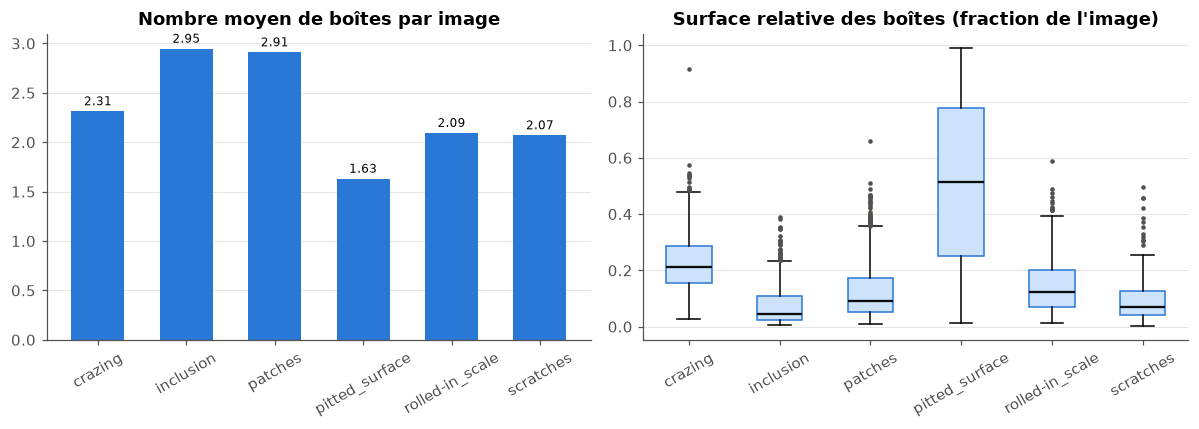

In [10]:
bx = boxes.merge(index[["filename", "label", "split"]], on="filename")
bx["area"] = bx.w * bx.h
per_img = index.groupby("label")["n_boxes"].describe()[["mean", "min", "max"]].reindex(CLASSES).round(2)
display(per_img.rename(columns={"mean": "boîtes/image (moy.)", "min": "min", "max": "max"}))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
data = [index.loc[index.label == c, "n_boxes"] for c in CLASSES]
axes[0].bar(CLASSES, [x.mean() for x in data], color=SERIES[0], width=0.6)
axes[0].bar_label(axes[0].containers[0], fmt="%.2f", padding=2, fontsize=8)
axes[0].set_title("Nombre moyen de boîtes par image")
axes[0].tick_params(axis="x", rotation=30)
axes[0].grid(axis="x", visible=False)

bp = axes[1].boxplot([bx.loc[bx.label == c, "area"] for c in CLASSES], tick_labels=CLASSES, widths=0.5,
                     patch_artist=True, medianprops={"color": TEXT, "linewidth": 1.5},
                     flierprops={"marker": "o", "markersize": 3, "markerfacecolor": MUTED, "markeredgecolor": "none"})
for patch in bp["boxes"]:
    patch.set(facecolor="#cde2fb", edgecolor=SERIES[0])
axes[1].set_title("Surface relative des boîtes (fraction de l'image)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].grid(axis="x", visible=False)
fig.tight_layout()
save(fig, "fig07_boxes_stats.png")
plt.show()

saved -> reports\figures\fig08_box_examples.png


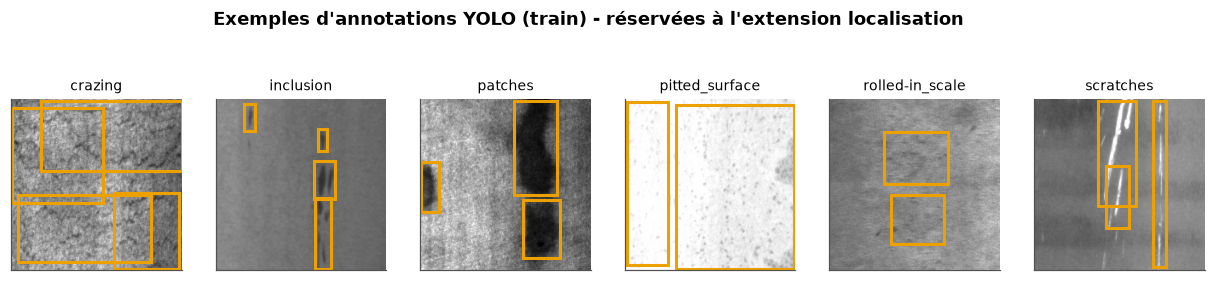

In [11]:
fig, axes = plt.subplots(1, len(CLASSES), figsize=(14, 2.9))
for ax, cls in zip(axes, CLASSES):
    f = index.query("label == @cls and split == 'train' and n_boxes > 1")["filename"]
    f = f.iloc[0] if len(f) else index.query("label == @cls and split == 'train'")["filename"].iloc[0]
    img = Image.open(NEU_RAW_DIR / "images" / f).convert("L")
    W, H = img.size
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    for b in boxes.query("filename == @f").itertuples():
        ax.add_patch(mpatches.Rectangle(((b.cx - b.w / 2) * W, (b.cy - b.h / 2) * H), b.w * W, b.h * H,
                                        fill=False, edgecolor=SERIES[3], linewidth=2))
    ax.set_title(cls, fontsize=9, fontweight="normal")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Exemples d'annotations YOLO (train) - réservées à l'extension localisation", fontweight="bold", y=1.04)
save(fig, "fig08_box_examples.png")
plt.show()

### 7.1 Images multi-défauts

Les annotations YOLO révèlent que certaines images contiennent, **en plus du défaut
dominant** (celui du nom de fichier), d'autres types de défauts. La classification
mono-étiquette attribue une seule classe : ces images sont une source d'ambiguïté
légitime, à surveiller lors de l'analyse des erreurs (phase 6).

Lignes : classe de l'image (nom de fichier) - colonnes : défaut secondaire annoté


secondary,inclusion,patches,pitted_surface,images multi-défauts,% de la classe
label,,,,,
crazing,1,4,0,5,1.7
inclusion,0,0,0,0,0.0
patches,29,0,0,29,9.7
pitted_surface,3,37,0,39,13.0
rolled-in_scale,0,0,0,0,0.0
scratches,49,1,1,50,16.7


has_secondary_defects,mono,multi
split,,
test,252,18
train,1177,83
val,248,22


saved -> reports\figures\fig09_multi_defect_examples.png


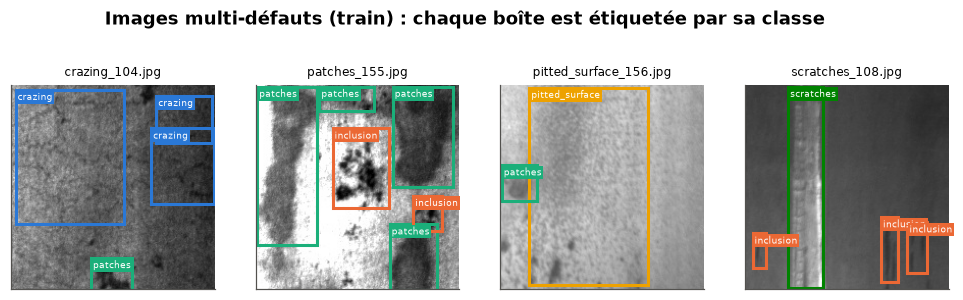

In [12]:
multi = index[index.has_secondary_defects]
sec = (multi.assign(secondary=multi.secondary_classes.astype(str).str.split(","))
            .explode("secondary").assign(secondary=lambda d: d.secondary.astype(int).map(dict(enumerate(CLASSES)))))
table = pd.crosstab(sec["label"], sec["secondary"]).reindex(index=CLASSES, fill_value=0)
table["images multi-défauts"] = multi.groupby("label").size().reindex(CLASSES, fill_value=0)
table["% de la classe"] = (table["images multi-défauts"] / index.label.value_counts().reindex(CLASSES) * 100).round(1)
print("Lignes : classe de l'image (nom de fichier) - colonnes : défaut secondaire annoté")
display(table)
display(pd.crosstab(index.split, index.has_secondary_defects).rename(columns={False: "mono", True: "multi"}))

fig, axes = plt.subplots(1, 4, figsize=(11, 3))
colors = dict(zip(range(len(CLASSES)), SERIES))
for ax, f in zip(axes, multi.query("split == 'train'").groupby("label").head(1)["filename"].head(4)):
    img = Image.open(NEU_RAW_DIR / "images" / f).convert("L"); W, H = img.size
    ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    for b in boxes.query("filename == @f").itertuples():
        ax.add_patch(mpatches.Rectangle(((b.cx - b.w / 2) * W, (b.cy - b.h / 2) * H), b.w * W, b.h * H,
                                        fill=False, edgecolor=colors[b.box_class], linewidth=2))
        ax.text((b.cx - b.w / 2) * W + 2, (b.cy - b.h / 2) * H + 10, CLASSES[b.box_class], fontsize=6,
                color="white", bbox={"facecolor": colors[b.box_class], "edgecolor": "none", "pad": 1})
    ax.set_title(f, fontsize=8, fontweight="normal"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
fig.suptitle("Images multi-défauts (train) : chaque boîte est étiquetée par sa classe", fontweight="bold", y=1.03)
save(fig, "fig09_multi_defect_examples.png")
plt.show()

## 8. Contrôle final du split

In [13]:
import subprocess, sys
res = subprocess.run([sys.executable, str(Path.cwd().parent / "scripts" / "verify_splits.py")],
                     capture_output=True, text=True, encoding="utf-8", cwd=Path.cwd().parent)
print(res.stdout or res.stderr)
assert res.returncode == 0, "La vérification du split a échoué"

[PASS] Dossiers = CSV de split: train=1260, val=270, test=270
[PASS] Aucun fichier partagé entre subsets: 0 overlap
[PASS] Groupes de doublons non scindés: 0 groupe(s) scindé(s)
[PASS] Proportions 70/15/15: train=1260, val=270, test=270 (écart max 0.0000)
[PASS] Stratification respectée: écart max de proportion = 0.0000
split            train  val  test
label                            
crazing            210   45    45
inclusion          210   45    45
patches            210   45    45
pitted_surface     210   45    45
rolled-in_scale    210   45    45
scratches          210   45    45
[PASS] Fichiers lisibles et taille attendue: 1800/1800 OK
[PASS] Aucun doublon exact entre subsets: 0 leak(s)
[PASS] Aucun quasi-doublon entre subsets: 0 leak(s), distance pHash minimale inter-subsets = 6

8/8 checks passed



## 9. Conclusions

Rédigées à partir des sorties ci-dessus (exécution du 14/11/2026, seed 42).

**Intégrité**
- 1 800 images, 6 classes x 300, toutes en 200x200. Les fichiers sont des JPEG « RGB », mais
  leurs 3 canaux sont identiques (100 %) : l'information est en **niveaux de gris**. Le CNN
  personnalisé travaillera sur 1 canal ; ResNet50 / MobileNetV2 recevront l'image dupliquée
  sur 3 canaux (format attendu par les poids ImageNet).
- Chaque image possède au moins une boîte YOLO, et la classe du nom de fichier figure
  toujours parmi ses boîtes (0 incohérence).

**Distribution et split**
- Dataset parfaitement équilibré : aucune pondération de la loss n'est nécessaire.
- Split stratifié 1 260 / 270 / 270 (210 / 45 / 45 par classe), reproductible (seed 42,
  CSV versionnés). 8/8 contrôles anti-fuite passés.

**Doublons**
- 1 doublon exact (`patches_101` = `patches_105`) et 1 quasi-doublon (`scratches_247` =
  `scratches_232` tourné de 90°, r = 0,957). Les deux paires sont dans le **même subset** (train).
- Sans l'invariance aux rotations, la seconde paire n'aurait pas été détectée.
- Les 2 autres candidats pHash (d = 6) ont une corrélation <= 0,42 : ce sont des images
  distinctes. L'écart entre 0,42 et 0,957 justifie le seuil de corrélation de 0,95.
- La distance au plus proche voisin a une médiane de 16 bits : les images sont en général
  bien distinctes.

**Risques identifiés pour la modélisation**
1. **Raccourci luminosité / contraste** : l'intensité moyenne varie fortement d'une classe
   à l'autre (moyennes de 95 pour *scratches* à 177 pour *pitted_surface*) ; le contraste
   aussi (*inclusion* environ 13, *patches* environ 54). Un modèle pourrait se baser sur ces
   statistiques globales plutôt que sur la forme du défaut. Réponses : augmentations
   modérées de luminosité / contraste, et contrôle avec Grad-CAM (phase 6).
2. **Artefact d'acquisition** : les images moyennes montrent un **bord droit plus sombre**
   pour plusieurs classes. À surveiller dans les cartes Grad-CAM.
3. **Images multi-défauts** : 123 images (6,8 %) contiennent un défaut secondaire annoté
   (surtout *scratches* + *inclusion*, *pitted_surface* + *patches*,
   *patches* + *inclusion*). L'étiquette mono-classe est donc parfois ambiguë ; ces images
   sont réparties dans les trois subsets (83 / 22 / 18) et seront analysées séparément lors
   de l'étude des erreurs.
4. Les rayures apparaissent dans les deux orientations (verticale et horizontale) : des
   rotations de 90° et des symétries sont des augmentations **physiquement plausibles**.

**Normalisation** (calculée sur le train uniquement) : moyenne = 0,5043, écart-type = 0,2125
(échelle 0-1), sauvegardées dans `datasets/splits/train_pixel_stats.json` pour le CNN personnalisé.

**Localisation (extension)** : 4 189 boîtes, de 1,6 à 3,0 boîtes par image en moyenne selon la
classe. La détection sera une tâche séparée qui réutilisera exactement le même split.